#  03 환각 여부를 평가하는 Agentic RAG

검색 문서의 관련성, 답변의 환각 여부, 답변의 유용성을 평가하는 완전한 Agentic RAG 시스템입니다.

문서 관련성 평가: 검색된 문서와 질문의 관련성 자동 평가

환각 평가: 생성된 답변이 검색된 문서에 기반하는지 검증

답변 유용성 평가: 답변이 질문을 해결하는지 평가

쿼리 재작성: 검색 성능 향상을 위한 자동 쿼리 개선

다중 분기 조건: 평가 결과에 따른 동적 워크플로우

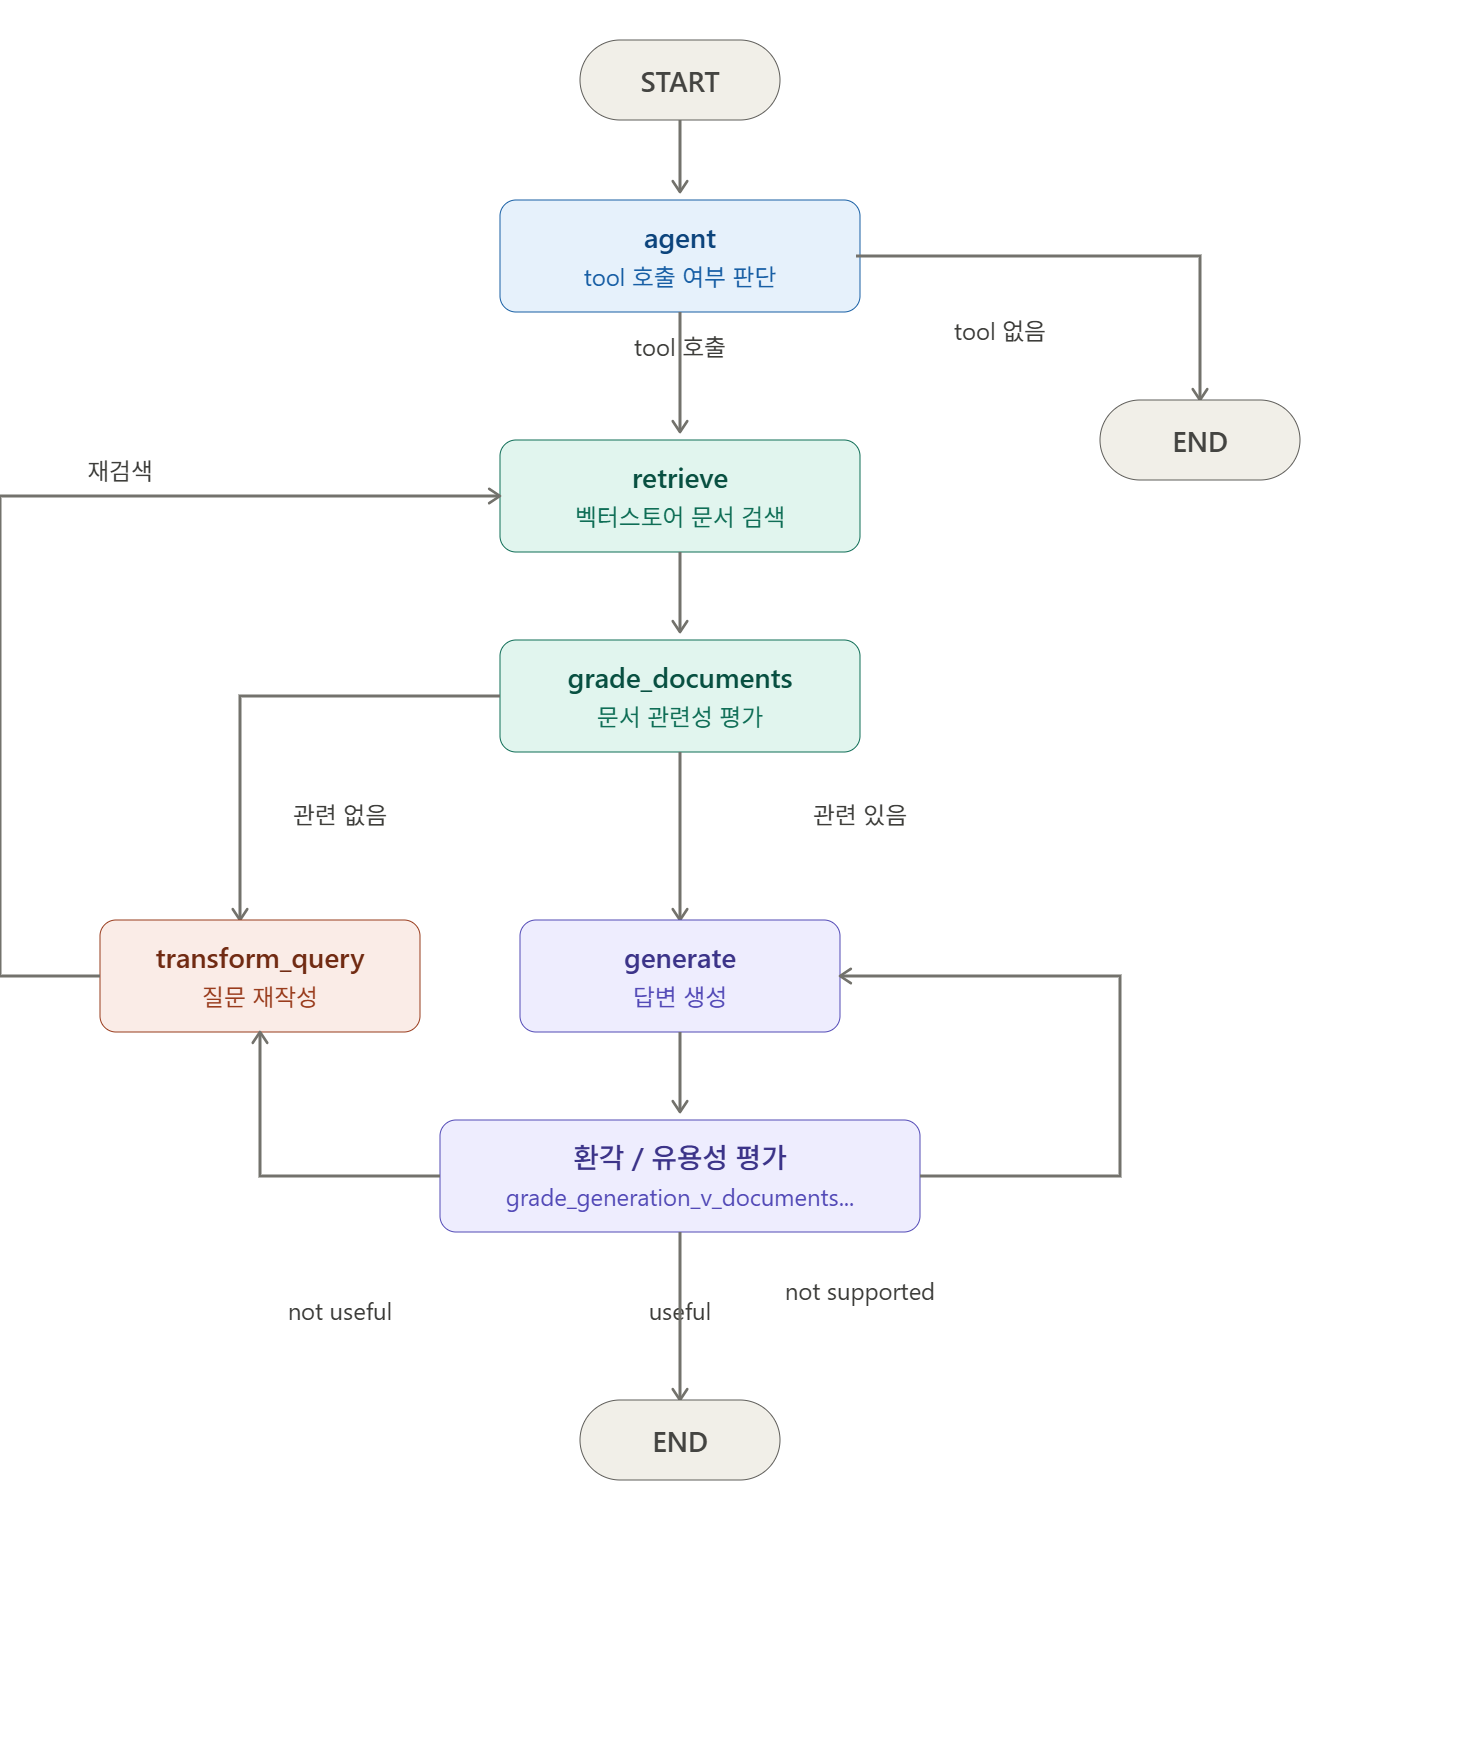

 # Graph State 정의

In [1]:
from langgraph.graph import MessagesState
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from typing_extensions import TypedDict
from typing import Optional

# .env 파일에 정의된 환경변수(API 키 등)를 불러옴
load_dotenv()


def _get_llm():
    # 사용할 LLM 모델을 초기화해서 반환하는 함수
    # init_chat_model: 모델명만 넘기면 적절한 chat model 객체를 생성해줌
    return init_chat_model("gpt-5-mini")


class InputState(TypedDict):
    # 그래프 진입 시 외부에서 받는 입력 상태 정의
    question: str  # 사용자가 입력한 질문


class OutputState(TypedDict):
    # 그래프 실행 종료 후 외부로 반환되는 출력 상태 정의
    generation: str  # LLM이 생성한 최종 답변


class State(MessagesState):
    # 그래프 내부에서 노드 간 공유되는 전체 상태 정의
    # MessagesState를 상속받아 messages 필드(대화 기록)를 기본으로 포함함
    question: Optional[str]    # 사용자 질문 (없을 수도 있어서 Optional)
    generation: Optional[str]  # LLM이 생성한 답변
    document: Optional[str]    # 검색/조회된 참고 문서 내용


 # Retriever 설정

def setup_retriever()

In [2]:
import fitz  # PyMuPDF: PDF 파싱 라이브러리
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_classic.retrievers import ParentDocumentRetriever
from langchain_core.stores import InMemoryByteStore
from langchain_core.tools import create_retriever_tool


def setup_retriever():
    file_path = "dataset/SPRi AI Brief 6월호.pdf"

    # --- 1. PyMuPDF로 PDF 문서 로드 ---
    doc = fitz.open(file_path)
    docs = []
    for page_num in range(len(doc)):
        page = doc[page_num]
        # sort=True: 텍스트 블록을 읽기 순서대로 정렬해서 추출
        text = page.get_text("text", sort=True)
        # 페이지별로 LangChain Document 객체로 변환 (페이지 = 추후 parent 문서 단위)
        docs.append(
            Document(
                page_content=text,
                metadata={
                    "source": file_path,
                    "page": page_num + 1  # 사람이 읽기 좋게 1부터 시작
                }
            )
        )
    doc.close()
    print(f"총 {len(docs)}페이지 로드 완료")

    # --- 2. child_splitter 정의 ---
    # parent(페이지) 안에서 더 작은 child 청크로 쪼개기 위한 splitter
    # 검색은 작은 child 단위로 정밀하게, 반환은 parent(페이지) 전체로 넓게
    child_splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50)

    # --- 3. 벡터스토어 생성 ---
    # child 청크들의 임베딩을 저장할 벡터DB (persist_directory 미지정 -> 메모리에만 존재)
    embeddings = OpenAIEmbeddings()
    vectorstore = Chroma(
        collection_name="june_doc",
        embedding_function=embeddings
    )

    # --- 4. docstore 생성 ---
    # parent 문서(페이지 원문)를 key-value로 저장할 인메모리 저장소
    docstore = InMemoryByteStore()

    # --- 5. ParentDocumentRetriever 생성 ---
    # child 단위로 유사도 검색 후, 매칭된 child가 속한 parent(페이지) 전체를 반환하는 retriever
    parent_retriever = ParentDocumentRetriever(
        vectorstore=vectorstore,
        docstore=docstore,
        child_splitter=child_splitter,
        parent_splitter=None,  # parent_splitter가 None이면 원본 Document(=페이지) 자체가 parent
        search_kwargs={"k": 1}  # 검색 시 child 청크 1개만 반환 (-> 해당 parent 페이지 1개로 매핑)
    )

    # --- 6. 문서를 retriever에 추가 ---
    # 내부적으로 child_splitter로 쪼개고, child는 vectorstore에, parent는 docstore에 저장
    print("문서를 벡터스토어에 추가 중...")
    parent_retriever.add_documents(docs)

    # 적재된 child/parent 개수 확인 (디버깅용)
    child_count = vectorstore._collection.count()
    parent_count = len(list(docstore.yield_keys()))
    print(f"child chunk 수: {child_count}, parent page 수: {parent_count}")

    # --- 7. Retriever를 LangChain Tool로 래핑 ---
    # LLM이 tool calling으로 호출할 수 있도록 retriever를 도구 형태로 변환
    retriever_tool = create_retriever_tool(
        parent_retriever,
        "retrieve_AI_brief",          # tool 이름 (LLM이 호출 시 참조)
        "AI 기술 관련 정보를 SPRi AI Brief에서 검색하고 반환합니다.",  # tool 설명 (LLM이 언제 쓸지 판단하는 기준)
    )

    return parent_retriever, retriever_tool

# 프롬프트 정의 (관련성, 환각, 답변 평가, 쿼리 재작성)

In [3]:
from langchain_core.prompts import ChatPromptTemplate

# 문서 관련성 평가 프롬프트
# - RAG 파이프라인에서 검색된 문서(context)가 질문(question)에 실제로 관련 있는지
#   LLM에게 yes/no로 판단시키기 위한 프롬프트 (관련성 평가 = grading)
RELEVANCE_GRADER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 사용자 질문에 대한 검색된 문서의 관련성을 평가하는 평가자입니다.

    <context>
    {context}
    </context>

    <question>
    {question}
    </question>

    문서가 사용자 질문과 관련된 키워드나 의미를 포함하고 있다면, 관련성이 있다고 평가하세요.
    엄격한 테스트일 필요는 없습니다. 목표는 잘못된 검색 결과를 걸러내는 것입니다.

    관련성이 있는 경우 'yes', 관련성이 없는 경우 'no'를 반환하세요.
    """
)
# 사용 시 {context}, {question} 두 변수를 채워서 호출
# 보통 structured output(예: Pydantic 모델 with literal "yes"/"no")과 함께 사용해
# LLM 응답을 바로 분기 로직(conditional edge)에 활용함

In [4]:
from langchain_core.prompts import ChatPromptTemplate

# 환각(hallucination) 평가 프롬프트
# - LLM이 생성한 답변(generation)이 검색된 문서(facts)에 실제로 근거하는지 검증
# - RAG 파이프라인의 self-correction 단계에서 사용 (생성 후 사후 검증)
HALLUCINATION_GRADER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 LLM이 생성한 답변이 검색된 사실에 근거하고 있는지 평가하는 평가자입니다.

    <facts>
    {document}
    </facts>

    <generation>
    {generation}
    </generation>

    답변이 주어진 사실에 근거하고 있으면 'yes', 그렇지 않으면 'no'를 반환하세요.
    'yes'는 답변이 사실 세트에 의해 뒷받침된다는 의미입니다.
    """
)
# 사용 시 {document}(검색된 사실), {generation}(LLM 답변) 두 변수를 채워서 호출
# 'no'가 나오면 보통 재생성(regenerate) 노드로 라우팅하는 conditional edge에 연결됨


In [5]:
from langchain_core.prompts import ChatPromptTemplate

# 답변 유용성(usefulness) 평가 프롬프트
# - 생성된 답변(generation)이 사용자 질문(question)의 의도를 실제로 충족하는지 평가
# - HallucinationGrader(사실 근거 여부)와는 별개로, "쓸모 있는 답변인가"를 판단
ANSWER_GRADER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 답변이 질문에 대해 유용한 정보를 제공하는지 평가하는 평가자입니다.

    <question>
    {question}
    </question>

    <generation>
    {generation}
    </generation>

    다음 기준으로 평가하세요:
    - 답변이 질문의 핵심 의도에 대응하는가?
    - 질문에서 요청한 정보를 실질적으로 제공하는가?
    - 답변 내용이 질문과 관련성이 있는가?

    답변이 질문에 대해 의미 있는 정보를 제공한다면 'yes'를 반환하세요.
    답변이 질문과 완전히 무관하거나 요청한 정보를 전혀 제공하지 않을 때만 'no'를 반환하세요.

    관대하게 평가하세요. 답변이 부분적으로라도 질문에 답하고 있다면 'yes'입니다.
    """
)
# 사용 시 {question}, {generation} 두 변수를 채워서 호출
# 'no'가 나오면 보통 쿼리 재작성(rewrite query) 노드로 라우팅하는 conditional edge에 연결됨
# (HallucinationGrader: 사실 근거 여부 / AnswerGrader: 질문 적합성 여부 -> 평가 관점이 다름)

In [6]:
from langchain_core.prompts import ChatPromptTemplate


# 쿼리 재작성 프롬프트
# - 관련성 평가(RELEVANCE_GRADER_PROMPT) 결과가 'no'일 때 호출되는 노드에서 사용
# - 원본 질문(question)의 의미적 의도를 추론해 검색에 더 적합한 형태로 다시 작성
QUERY_REWRITER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 입력된 질문을 벡터스토어 검색에 최적화된 더 나은 버전으로 변환하는 질문 재작성자입니다.
    입력을 보고 근본적인 의미적 의도를 추론하세요.

    <question>
    {question}
    </question>

    위 질문을 개선하여 한국어로 재작성하세요.
    """
)
# 사용 시 {question} 변수만 채워서 호출
# 재작성된 질문은 다시 retriever_tool 검색 단계로 보내져 재검색을 유도함


# 노드 함수들

In [7]:
# 모듈 레벨에서 한 번만 초기화
# (그래프 노드 함수들이 호출될 때마다 매번 새로 만들지 않도록, import 시점에 한 번만 생성해서 재사용)
retriever, retriever_tool = setup_retriever()  # ParentDocumentRetriever와 이를 감싼 retriever_tool 생성
llm = _get_llm()  # 그래프 전반에서 공통으로 사용할 LLM 인스턴스 생성

총 28페이지 로드 완료
문서를 벡터스토어에 추가 중...
child chunk 수: 191, parent page 수: 28


def agent(state: State):

In [8]:
from langchain_core.messages import HumanMessage, SystemMessage

def agent(state: State):
    """
    LLM이 사용자 질문을 분석하고 필요시 Retriever Tool을 호출합니다.
    """
    print("##### AGENT #####")

    # 그래프 state에서 사용자 질문 추출
    question = state["question"]
    print(f"Using original question: {question}")

    # LLM에 전달할 메시지 구성 (사용자 질문만 HumanMessage로 감쌈)
    messages = [HumanMessage(content=question)]

    # LLM에 retriever_tool을 바인딩 -> LLM이 필요하다고 판단하면 tool_calls를 생성함
    llm_with_tools = llm.bind_tools([retriever_tool])
    response = llm_with_tools.invoke(messages)

    print(f"Response: {response}")

    # messages: add_messages 리듀서에 의해 기존 메시지 목록에 누적됨
    # question: 다음 노드에서도 참조할 수 있도록 그대로 유지
    # generation: LLM의 응답 텍스트 (tool 호출만 했다면 비어있을 수 있음에 유의)
    return {"messages": [response], "question": question, "generation": response.content}

def retrieve(state: State):

In [9]:
def retrieve(state: State):
    """
    벡터스토어에서 관련 문서를 검색합니다.
    """
    print("##### RETRIEVE #####")

    # 그래프 state에서 사용자 질문 추출
    question = state["question"]
    print(f"Question: {question}")

    # parent_retriever로 문서 검색 (child 매칭 -> parent 페이지 단위로 반환됨)
    document = retriever.invoke(question)

    # 검색된 문서들을 하나의 문자열로 합쳐서 context 구성
    # (주석에는 "리스트로 저장"이라고 되어 있지만, 실제로는 문자열로 concat하고 있음 -> 의도 확인 필요)
    context = ""
    for idx, doc in enumerate(document):
        context += f"Document {idx + 1}:\n{doc.page_content}\n문서 페이지: {doc.metadata['page']}\n"
        print(f"Retrieved Document {idx + 1}: {doc.page_content[:100]}...")

    # document: 검색된 문서들을 합친 context 문자열 (HALLUCINATION_GRADER_PROMPT의 {document}로 사용될 값)
    # question: 다음 노드에서도 참조할 수 있도록 그대로 유지
    return {"document": context, "question": question}

def grade_documents(state: State):

In [10]:
from pydantic import BaseModel, Field

class Grade(BaseModel):
    """Binary score for relevance check."""
    # LLM의 structured output을 강제하기 위한 Pydantic 모델
    # (llm.with_structured_output(Grade) 형태로 사용하면, LLM이 이 스키마에 맞춰 응답을 생성함)
    binary_score: str = Field(description="Relevance score 'yes' or 'no'")
    # binary_score: 'yes' 또는 'no' 둘 중 하나의 문자열만 들어오길 기대
    # (참고: 현재는 type이 str이라 다른 값도 허용됨. 값을 엄격히 제한하려면
    #  Literal["yes", "no"]로 바꾸는 게 더 안전함)

In [11]:
def grade_documents(state: State):
    """
    검색된 문서가 질문과 관련이 있는지 평가합니다.
    """
    print("##### CHECK RELEVANCE #####")

    # state에서 질문과 검색된 문서(context) 추출
    question = state["question"]
    document = state["document"]

    # 관련성 평가용 LLM + structured output 구성
    # (모듈 레벨 llm을 안 쓰고 여기서 새로 생성 -> 다른 노드들과의 일관성 확인 필요)
    llm = _get_llm()
    grader = llm.with_structured_output(Grade)  # 응답을 Grade 스키마(binary_score)로 강제
    chain = RELEVANCE_GRADER_PROMPT | grader     # 프롬프트 -> grader로 이어지는 체인 구성

    # 관련성 평가 실행
    score = chain.invoke({"question": question, "context": document})
    grade = score.binary_score

    print(f"Question: {question}")
    print(f"Context: {document[:100]}...")
    print(f"Grade: {grade}")

    if grade == "yes":
        print("---GRADE: DOCUMENT RELEVANT---")
        # 관련 있음 -> 문서 그대로 유지
        return {"document": document, "question": question}
    else:
        print("---GRADE: DOCUMENT NOT RELEVANT---")
        # 관련 없음 -> document를 빈 문자열로 초기화 (다음 노드에서 "문서 없음"으로 판단 가능)
        return {"document": "", "question": question}

def generate(state: State):

In [12]:
def generate(state: State):
    """
    검색된 문서를 기반으로 최종 답변을 생성합니다.
    """
    print("##### GENERATE #####")

    # state에서 질문과 (관련성 검증을 통과한) 문서 context 추출
    question = state["question"]
    document = state["document"]
    print(f"Question: {question}")
    print(f"Context: {document[:100]}...")

    # RAG 답변 생성용 LLM (여기서도 모듈 레벨 llm 대신 새로 생성하고 있음 - grade_documents와 동일 패턴)
    llm = _get_llm()

    # 시스템 프롬프트: 답변 형식/스타일 지시 (마크다운, 출처 표기, 후속 질문 추천 금지 등)
    SYSTEM_PROMPT = """
    당신은 관련 문서를 기반으로 답변하는 어시스턴트입니다.
    주어진 문서 텍스트를 기반으로 사용자의 질문에 대해 충실히 답변하세요.
    답변은 마크다운 문법 형식으로 적절한 볼드체, 제목, 불렛 등을 사용하여 가독성 좋게 작성하세요.
    문서의 출처(문서의 원본 출처와 페이지 출처)도 함께 명시하세요.
    확장 가능한 질문은 추천하지 마세요.
    """
    system_msg = SystemMessage(SYSTEM_PROMPT)

    # 사용자 메시지: context(검색 문서)와 question을 함께 포함시켜 LLM에 전달
    human_msg = HumanMessage(f"""
    다음은 주어진 문서 텍스트입니다.
    <context>
    {document}
    </context>
    <question>
    {question}
    </question>
    """)

    # 시스템+사용자 메시지로 답변 생성 호출
    response = llm.invoke([system_msg, human_msg])
    print(f"Response: {response.content[:100]}...")

    return {
        "document": document,      
        "question": question,
        "generation": response.content,  # 최종 생성된 답변 (HallucinationGrader, AnswerGrader의 입력으로 사용됨)
        "messages": [response]      # add_messages 리듀서로 누적
    }

def transform_query(state: State):

In [13]:
def transform_query(state: State):
    """
    검색 성능 향상을 위해 질문을 재작성합니다.
    """
    print("##### TRANSFORM QUERY #####")

    # 재작성 대상이 되는 원본(또는 이전 단계) 질문
    question = state["question"]

    # 쿼리 재작성 체인 구성 (여기서도 모듈 레벨 llm 대신 새로 생성 - 다른 노드들과 동일 패턴)
    llm = _get_llm()
    question_rewriter = QUERY_REWRITER_PROMPT | llm
    better_question = question_rewriter.invoke({"question": question})

    print(f"Original Question: {question}")
    print(f"Better Question: {better_question.content}")

    # question: 재작성된 질문 문자열로 갱신 -> 이후 retrieve 노드에서 재검색에 사용됨
    # messages: 재작성 과정도 대화 기록에 누적 (AIMessage 형태로 쌓임)
    return {
        "question": better_question.content,
        "messages": [better_question]
    }

# 엣지 조건 함수

In [14]:
from typing import Literal
from langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field

# ===============================
# 엣지 조건 함수
# ===============================

class GradeHallucinations(BaseModel):
    """Binary score for hallucination present in generation answer."""
    # 생성된 답변이 검색된 문서(facts)에 근거하는지를 나타내는 structured output 스키마
    binary_score: str = Field(
        description="Answer is grounded in the facts, 'yes' or 'no'"
    )


class GradeAnswer(BaseModel):
    """Binary score to assess answer addresses question."""
    # 생성된 답변이 질문의 의도를 실질적으로 충족하는지를 나타내는 structured output 스키마
    binary_score: str = Field(
        description="Answer addresses the question, 'yes' or 'no'"
    )


def decide_to_generate(state: State) -> Literal["transform_query", "generate"]:
    """
    문서 관련성에 따라 답변 생성 또는 쿼리 재작성을 결정합니다.
    관련성 있음 -> generate, 관련성 없음 -> transform_query
    """
    print("##### ASSESS GRADED DOCUMENTS #####")

    # grade_documents 노드에서 관련성이 없다고 판단되면 document를 ""로 비워뒀으므로,
    # 그 값을 보고 분기 결정 (-> add_conditional_edges에서 이 함수의 반환값으로 다음 노드를 선택)
    if state["document"] == "":
        print("---DECISION: TRANSFORM QUERY---")
        return "transform_query"  # 관련 문서 없음 -> 쿼리 재작성 후 재검색
    else:
        print("---DECISION: GENERATE---")
        return "generate"  # 관련 문서 있음 -> 답변 생성으로 진행


def grade_generation_v_documents_and_question(state: State) -> Literal["useful", "not useful", "not supported"]:
    """
    생성된 답변의 환각 여부와 유용성을 평가합니다.
    useful: 환각 없고 유용함 | not useful: 환각 없지만 유용하지 않음 | not supported: 환각 발생
    """
    print("##### CHECK HALLUCINATIONS #####")

    # state에서 질문, 근거 문서, 생성된 답변 추출
    question = state["question"]
    document = state["document"]
    generation = state["generation"]

    # --- 1단계: 환각(hallucination) 평가 ---
    # 생성된 답변이 document(근거 문서)에 실제로 뒷받침되는지 확인
    llm = _get_llm()
    hallucination_grader = llm.with_structured_output(GradeHallucinations)
    hallucination_chain = HALLUCINATION_GRADER_PROMPT | hallucination_grader
    score = hallucination_chain.invoke({
        "document": document,
        "generation": generation
    })
    grade = score.binary_score

    if grade == "yes":  # 환각 없음 (근거 있음)
        print("---DECISION: GENERATION IS GROUNDED IN DOCUMENTS---")

        # --- 2단계: 답변 유용성 평가 ---
        # 환각이 없다는 게 확인된 경우에만, 답변이 질문에 실질적으로 유용한지 추가 평가
        llm = _get_llm()
        answer_grader = llm.with_structured_output(GradeAnswer)
        answer_chain = ANSWER_GRADER_PROMPT | answer_grader
        print(question)
        print(generation)
        score = answer_chain.invoke({
            "question": question,
            "generation": generation
        })
        grade = score.binary_score

        if grade == "yes":  # 유용함
            print("---DECISION: GENERATION ADDRESSES QUESTION---")
            return "useful"  # 최종 답변으로 채택 가능 -> 그래프 종료(END)로 라우팅
        else:  # 유용하지 않음
            print("---DECISION: GENERATION DOES NOT ADDRESS QUESTION---")
            return "not useful"  # 근거는 있지만 질문과 안 맞음 -> 쿼리 재작성으로 라우팅
    else:  # 환각 발생 (근거 없음)
        print("---DECISION: GENERATION IS NOT GROUNDED IN DOCUMENTS, RE-TRY---")
        return "not supported"  # 근거 부족 -> 답변 재생성(generate)으로 라우팅

# 그래프 구성

In [15]:
from langgraph.graph import END, StateGraph, START
from langgraph.prebuilt import tools_condition


def create_agent_graph():
    # StateGraph 생성
    # - 내부 상태는 State(전체 필드 보유)
    # - 외부 입력은 InputState(question만), 외부 출력은 OutputState(generation만)로 제한
    graph_builder = StateGraph(State, input_schema=InputState, output_schema=OutputState)

    # --- 노드 추가 ---
    graph_builder.add_node("agent", agent)                      # LLM이 질문 분석 + 필요시 tool 호출 결정
    graph_builder.add_node("retrieve", retrieve)                  # 벡터스토어에서 문서 검색
    graph_builder.add_node("grade_documents", grade_documents)    # 검색된 문서의 관련성 평가
    graph_builder.add_node("generate", generate)                  # 문서 기반 답변 생성
    graph_builder.add_node("transform_query", transform_query)    # 검색 성능 향상을 위한 질문 재작성

    # --- 엣지 연결 ---

    # 시작 -> agent 노드로 진입
    graph_builder.add_edge(START, "agent")

    # agent 조건부 엣지: tools_condition은 LLM 응답에 tool_calls가 있는지 자동 판별하는 LangGraph prebuilt 함수
    # - tool 호출 있음 -> "tools" 분기 -> 여기서는 retrieve로 매핑 (실제 도구 실행 대신 우리가 만든 retrieve 노드로 직접 라우팅)
    # - tool 호출 없음 -> END 분기 -> 그대로 종료 (LLM이 도구 없이 바로 답한 경우)
    graph_builder.add_conditional_edges(
        "agent",
        tools_condition,
        {
            "tools": "retrieve",
            END: END,
        },
    )

    # retrieve -> grade_documents (검색 후 항상 관련성 평가로 이어짐)
    graph_builder.add_edge("retrieve", "grade_documents")

    # grade_documents 조건부 엣지: decide_to_generate의 반환값에 따라 분기
    # - "transform_query": 관련 문서 없음 -> 질문 재작성
    # - "generate": 관련 문서 있음 -> 답변 생성
    graph_builder.add_conditional_edges(
        "grade_documents",
        decide_to_generate,
        {
            "transform_query": "transform_query",
            "generate": "generate",
        },
    )

    # transform_query -> retrieve (재작성된 질문으로 다시 검색하는 루프)
    graph_builder.add_edge("transform_query", "retrieve")

    # generate 조건부 엣지: grade_generation_v_documents_and_question의 반환값에 따라 분기
    # - "not supported": 환각 발생(근거 부족) -> generate로 되돌아가 재생성
    # - "useful": 환각 없고 유용함 -> 그래프 종료
    # - "not useful": 환각 없지만 질문과 안 맞음 -> transform_query로 보내 쿼리 재작성 후 재검색
    graph_builder.add_conditional_edges(
        "generate",
        grade_generation_v_documents_and_question,
        {
            "not supported": "generate",
            "useful": END,
            "not useful": "transform_query",
        },
    )

    # 그래프를 실행 가능한 형태로 컴파일
    graph = graph_builder.compile()
    return graph

In [16]:
 # 그래프 생성
graph =  create_agent_graph()


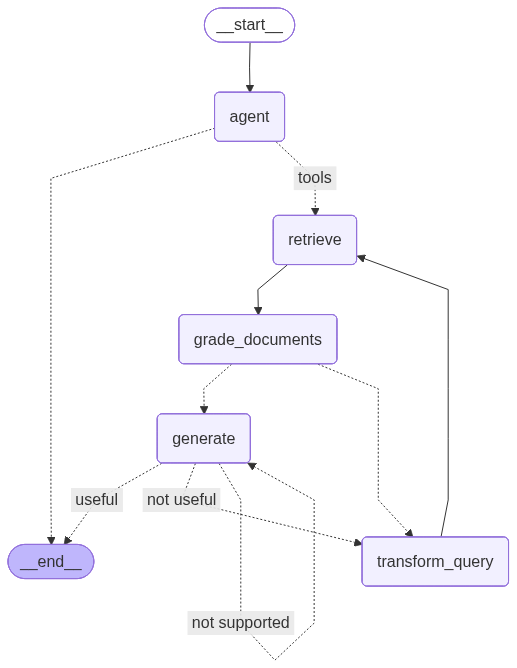

In [17]:
graph 

# Gradio 실행

---

In [21]:
def run_agent(question: str):
    """
    질문을 받아 LangGraph 실행 -> 최종 답변 + 실행 과정/출처를 함께 반환합니다.
    """
    if not question or not question.strip():
        return "질문을 입력해주세요."

    process_log = []  # 노드별 실행 과정을 기록
    final_state = {}

    # stream_mode="values": 각 노드 실행 후 누적된 전체 state를 순서대로 받음
    for step in graph.stream(
        {"question": question},
        config={"recursion_limit": 25},
        stream_mode="values"
    ):
        final_state = step  # 가장 마지막 step이 최종 상태

        # 어느 노드를 거쳤는지는 state에 어떤 키가 채워졌는지로 유추
        if step.get("document"):
            preview = step["document"][:150].replace("\n", " ")
            process_log.append(f"📄 **검색된 문서**: {preview}...")

    # 최종 답변
    answer = final_state.get("generation", "답변을 생성하지 못했습니다.")

    # 출처 추출 (document 안에 "문서 페이지" 형식으로 들어있음)
    document = final_state.get("document", "")
    sources = []
    for line in document.split("\n"):
        if "문서 페이지" in line:
            sources.append(line.strip())
    sources_text = "\n".join(sources) if sources else "출처 정보 없음"

    # 답변 + 실행 과정 + 출처를 함께 묶어서 반환
    full_response = f"""{answer}

---
**📚 참고 출처**
{sources_text}

**🔍 실행 과정**
{chr(10).join(process_log) if process_log else "(기록 없음)"}
"""
    return full_response

In [22]:
import gradio as gr

with gr.Blocks(title="AI Brief RAG 챗봇") as demo:
    gr.Markdown("## SPRi AI Brief 기반 RAG 챗봇")
    gr.Markdown("문서 검색 -> 관련성 평가 -> 답변 생성 -> 환각/유용성 평가를 거쳐 답변합니다.")

    chatbot = gr.Chatbot(label="대화", height=550, type="messages")
    question_box = gr.Textbox(
        label="질문 입력",
        placeholder="예: 6월 AI Brief에서 주요 정책 동향은?",
        lines=1,
    )
    with gr.Row():
        submit_btn = gr.Button("질문하기", variant="primary")
        clear_btn = gr.ClearButton([question_box, chatbot], value="대화 초기화")

    def respond(message, chat_history):
        chat_history = chat_history + [{"role": "user", "content": message}]
        answer = run_agent(message)
        chat_history = chat_history + [{"role": "assistant", "content": answer}]
        return "", chat_history

    question_box.submit(respond, [question_box, chatbot], [question_box, chatbot])
    submit_btn.click(respond, [question_box, chatbot], [question_box, chatbot])

In [23]:
demo.launch(inline=True, share=False, debug=True)

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


##### AGENT #####
Using original question: 6월 AI Brief에서 주요 정책 동향은?"
Response: content='' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 96, 'prompt_tokens': 154, 'total_tokens': 250, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-DtoYUrkbmPZBy4N5zCu5asUhbpvcj', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None} id='lc_run--1010e2a1-ac6a-43de-9235-85005f797b03-0' tool_calls=[{'name': 'retrieve_AI_brief', 'args': {'query': '6월 AI Brief 주요 정책 동향'}, 'id': 'call_qvQdf5SqL2J2Kc6BwV1IrUO8', 'type': 'tool_call'}] usage_metadata={'input_tokens': 154, 'output_tokens': 96, 'total_tokens': 250, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_